In [25]:
#!pip install scipy

In [26]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

# Définition des symboles nécessaires pour la suite
x_sym = sp.symbols('x')
L_sym, T0_sym, lam_sym = sp.symbols('L T0 lambda')

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Paramètres physiques et numériques
L = 10.0
T0 = 1.0  # Normalisé
lam = 1.0 # Lambda
K = 2     # Nombre d'éléments (pour correspondre à dim=2K+1)
h = L / (2 * (K + 1))
dim = 2 * K + 1

x_range = np.linspace(0, L, 500)

In [28]:
def tau_i(i, x_val, h):
    # On utilise sp.Piecewise pour que ce soit compatible avec l'intégration symbolique
    if i % 2 != 0: # tauimpair (Indices impairs)
        left, right = (i-1)*h, (i+1)*h
        return sp.Piecewise(
            (-(x_val - left) * (x_val - right) / (h**2), (x_val >= left) & (x_val <= right)),
            (0.0, True)
        )
    else: # taupair (Indices pairs)
        left_ext, mid, right_ext = (i-2)*h, (i-1)*h, i*h

        return sp.Piecewise(
            (((x_val - left_ext)*(x_val - mid)) / (2*h**2), (x_val >= left_ext) & (x_val <= right_ext)),
            (((x_val - (i+1)*h)*(x_val - (i+2)*h)) / (2*h**2), (x_val > right_ext) & (x_val <= (i+2)*h)),
            (0.0, True)
        )

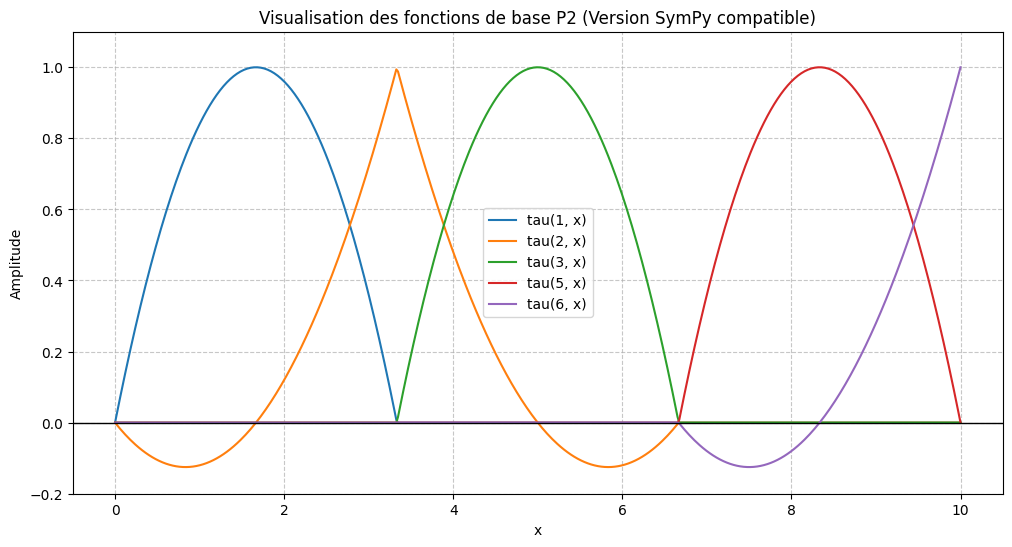

In [29]:
# Choix des indices à tracer
indices_a_tracer = [1,  K, K+1,  2*K+1, 2*K+2]
plt.figure(figsize=(12, 6))

for i in indices_a_tracer:
    # On vérifie si l'indice existe pour le maillage actuel (dim)
    if i <= dim+1:
        # On convertit l'expression SymPy de tau_i en fonction numérique "lambda"
        # pour pouvoir l'appliquer sur tout le tableau x_range d'un coup
        tau_num = sp.lambdify(x_sym, tau_i(i, x_sym, h), 'numpy')
        y_vals = tau_num(x_range)

        plt.plot(x_range, y_vals, label=f'tau({i}, x)')

plt.title("Visualisation des fonctions de base P2 (Version SymPy compatible)")
plt.xlabel("x")
plt.ylabel("Amplitude")
plt.axhline(0, color='black', linewidth=1)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.ylim(-0.2, 1.1)
plt.show()

In [30]:
def source(x):
    return (lam * T0 * x**2) / (L**4)

ML = np.zeros(dim)
for i in range(1, dim + 1):
    # On intègre numériquement sur le support de la fonction
    val, _ = quad(lambda x: tau_i(i, x, h) * source(x), 0, L)
    ML[i-1] = val

print("Vecteur ML :", ML)

Vecteur ML : [0.00074074 0.00111111 0.00567901 0.00481481 0.01555556]


In [31]:
def d_tau_i(i, x_val, h):
    # Dérivée numérique locale de la fonction de base
    eps = 1e-6
    return (tau_i(i, x_val + eps, h) - tau_i(i, x_val - eps, h)) / (2 * eps)

Rig = np.zeros((dim, dim))
for i in range(1, dim + 1):
    for j in range(1, dim + 1):
        # Intégration du produit des dérivées
        val, _ = quad(lambda x: lam * d_tau_i(i, x, h) * d_tau_i(j, x, h), 0, L)
        Rig[i-1, j-1] = val

print("Matrice de Rigidité :\n", Rig)

Matrice de Rigidité :
 [[ 1.6 -0.8  0.   0.   0. ]
 [-0.8  1.4 -0.8  0.1  0. ]
 [ 0.  -0.8  1.6 -0.8  0. ]
 [ 0.   0.1 -0.8  1.4 -0.8]
 [ 0.   0.   0.  -0.8  1.6]]


In [32]:
# Résolution
Msol = np.linalg.solve(Rig, ML)

# Reconstruction de la solution approchée TempEF
def TempEF(x_val):
    res = 0
    for i in range(1, dim + 1):
        res += Msol[i-1] * tau_i(i, x_val, h)
    return res / T0

In [33]:
# 1. Définition des symboles
x_sym = sp.symbols('x')
L_sym, T0_sym, lam_sym = sp.symbols('L T0 lambda')
T = sp.Function('T')

# 2. Définition de la source (Source: 29, 30)
# Équivalent Maple : source := x -> lambda * T0 * x^2 / L^4
source_sym = (lam_sym * T0_sym * x_sym**2) / L_sym**4

# 3. Définition de l'équation différentielle (Source: 59)
# Équivalent Maple : -lambda * diff(TT(x),x,x) = source(x)
equation = sp.Eq(-lam_sym * T(x_sym).diff(x_sym, x_sym), source_sym)

# 4. Résolution avec conditions aux limites (Source: 59, 62)
# Équivalent Maple : dsolve({eq, TT(0)=0, TT(L)=0}, TT(x))
sol_analytique = sp.dsolve(equation, T(x_sym), ics={T(0): 0, T(L_sym): 0})

# 5. Extraction et affichage de l'expression
Texact_expr = sol_analytique.rhs
print("La solution exacte trouvée par Python (Texact) est :")
display(Texact_expr)

# 6. Création d'une fonction numérique pour le tracé
# On renomme Texact_num en Texact0_sym pour la cohérence avec le calcul d'erreur
Texact0_sym = Texact_expr.subs({L_sym: 10, T0_sym: 1, lam_sym: 1})
f_exacte = sp.lambdify(x_sym, Texact0_sym, 'numpy')

La solution exacte trouvée par Python (Texact) est :


T0*x/(12*L) - T0*x**4/(12*L**4)

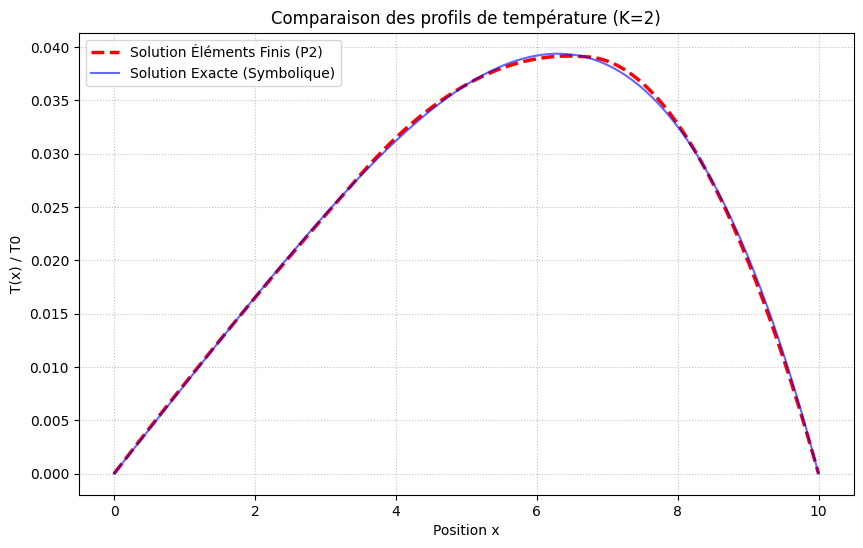

In [34]:
# 1. Conversion de la solution EF symbolique en fonction numérique
# (On somme les coefficients Msol multipliés par les fonctions de base)
TempEF_sym = sum((Msol[i-1]/T0) * tau_i(i, x_sym, h) for i in range(1, dim + 1))
f_EF_num = sp.lambdify(x_sym, TempEF_sym, 'numpy')

# 2. Génération des points de courbe
y_EF = f_EF_num(x_range)
y_exact = f_exacte(x_range)

# 3. Création du graphique
plt.figure(figsize=(10, 6))
plt.plot(x_range, y_EF, 'r--', label='Solution Éléments Finis (P2)', linewidth=2.5)
plt.plot(x_range, y_exact, 'b', label='Solution Exacte (Symbolique)', alpha=0.6)

plt.title(f"Comparaison des profils de température (K={K})")
plt.xlabel("Position x")
plt.ylabel("T(x) / T0")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.8)
plt.show()

In [35]:
# 1. Définition de la source symbolique (f)
f_sym = (lam_sym * T0_sym * x_sym**2) / L_sym**4
f_num = f_sym.subs({L_sym: 10, T0_sym: 1, lam_sym: 1})

# 2. Calcul pour la solution exacte (J = 1/2*a(u,u) - L(u))
a_exact = sp.integrate(sp.diff(Texact0_sym, x_sym)**2, (x_sym, 0, L))
L_exact = sp.integrate(f_num * Texact0_sym, (x_sym, 0, L))
J_exact = 0.5 * a_exact - L_exact

# 3. Calcul pour la solution Éléments Finis
a_EF = sp.integrate(sp.diff(TempEF_sym, x_sym)**2, (x_sym, 0, L))
L_EF = sp.integrate(f_num * TempEF_sym, (x_sym, 0, L))
J_EF = 0.5 * a_EF - L_EF

# 4. Calcul de l'erreur relative avec valeur absolue au dénominateur
erreur_J = (J_EF - J_exact) / abs(J_exact)

# 5. Affichage des résultats
print(f"{'Grandeur':<20} | {'Valeur':<15}")
print("-" * 45)
print(f"{'J(Exacte)':<20} | {J_exact.evalf():.10f}")
print(f"{'J(EF)':<20} | {J_EF.evalf():.10f}")
print(f"{'Erreur relative J':<20} | {erreur_J.evalf():.10f}")
print("-" * 45)

Grandeur             | Valeur         
---------------------------------------------
J(Exacte)            | -0.0004464286
J(EF)                | -0.0004453145
Erreur relative J    | 0.0024955545
---------------------------------------------


In [36]:
# Cette commande efface toutes les variables en mémoire pour repartir de zéro
%reset -f

# Message de confirmation
print("L'espace de travail a été réinitialisé.")
print("Veuillez maintenant cliquer sur 'Run' > 'Run All Cells' pour valider le TP.")

L'espace de travail a été réinitialisé.
Veuillez maintenant cliquer sur 'Run' > 'Run All Cells' pour valider le TP.
